# Antimicrobial Peptide Prediction with ESM-2 (8M) vs Classic Features
**Author:** Zainab Javed · BS Bioinformatics, Quaid-i-Azam University

Antimicrobial peptides (AMPs) are short proteins that kill bacteria and are candidates for new
antibiotics. Here I compare simple amino-acid composition features against embeddings from
the ESM-2 protein language model on the public **AMP Scanner v2** benchmark
(Veltri et al., *Bioinformatics* 2018), using its official train / eval / test split.

Full code, tests and CI: https://github.com/zainab-123-spec/antimicrobial-peptide-predictor

> Settings → turn **Internet on** (the notebook downloads the FASTA files from GitHub and the
> ESM-2 weights from Hugging Face). CPU is enough: the whole notebook takes a few minutes.

In [1]:
import urllib.request, itertools
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, matthews_corrcoef, accuracy_score, roc_curve

COMMIT = "16d48ef78d150853bd4bd8a3b18b50b03a357a85"
BASE = f"https://raw.githubusercontent.com/dan-veltri/amp-scanner-v2/{COMMIT}/original-dataset/"
AA = "ACDEFGHIKLMNPQRSTVWY"

def parse_fasta(text):
    recs, name, buf = [], None, []
    for line in text.splitlines():
        line = line.strip()
        if line.startswith(">"):
            if name is not None:
                recs.append("".join(buf).upper())
            name, buf = line[1:], []
        elif line:
            buf.append(line)
    if name is not None:
        recs.append("".join(buf).upper())
    return recs

def load(short):
    seqs, labels = [], []
    for kind, lab in (("AMP", 1), ("DECOY", 0)):
        text = urllib.request.urlopen(BASE + f"{kind}.{short}.fa").read().decode()
        for s in parse_fasta(text):
            if s and all(c in AA for c in s):
                seqs.append(s); labels.append(lab)
    return seqs, np.array(labels)

(tr_s, y_tr), (ev_s, y_ev), (te_s, y_te) = load("tr"), load("eval"), load("te")
print(len(tr_s), len(ev_s), len(te_s))

1424 708 1424


## 1. Classic features: amino-acid composition, dipeptides, physico-chemistry

In [2]:
KD = dict(A=1.8,R=-4.5,N=-3.5,D=-3.5,C=2.5,Q=-3.5,E=-3.5,G=-0.4,H=-3.2,I=4.5,
          L=3.8,K=-3.9,M=1.9,F=2.8,P=-1.6,S=-0.8,T=-0.7,W=-0.9,Y=-1.3,V=4.2)
DP = {"".join(p): i for i, p in enumerate(itertools.product(AA, repeat=2))}

def feats(s):
    n = len(s)
    aac = [s.count(a) / n for a in AA]
    dpc = np.zeros(400)
    for i in range(n - 1):
        dpc[DP[s[i:i+2]]] += 1
    dpc = dpc / max(dpc.sum(), 1)
    h = np.array([KD[a] for a in s]); ang = np.deg2rad(100) * np.arange(n)
    moment = np.hypot((h*np.cos(ang)).sum(), (h*np.sin(ang)).sum()) / n
    phys = [n, s.count("K")+s.count("R")-s.count("D")-s.count("E"),
            sum(s.count(a) for a in "KR")/n, sum(s.count(a) for a in "DE")/n,
            sum(s.count(a) for a in "AILMFVW")/n, sum(s.count(a) for a in "FWY")/n, h.mean(), moment]
    return np.concatenate([aac, dpc, phys])

F_tr, F_ev, F_te = (np.array([feats(s) for s in S]) for S in (tr_s, ev_s, te_s))
F_trev, y_trev = np.vstack([F_tr, F_ev]), np.concatenate([y_tr, y_ev])

## 2. ESM-2 embeddings (mean of per-residue vectors)

In [3]:
import torch
from transformers import AutoTokenizer, AutoModel
name = "facebook/esm2_t6_8M_UR50D"
tok, model = AutoTokenizer.from_pretrained(name), AutoModel.from_pretrained(name).eval()

def embed(seqs, bs=32):
    out = []
    with torch.no_grad():
        for i in range(0, len(seqs), bs):
            enc = tok(seqs[i:i+bs], return_tensors="pt", padding=True)
            hid = model(**enc).last_hidden_state
            mask = enc["attention_mask"].clone(); mask[:, 0] = 0
            mask[torch.arange(len(mask)), enc["attention_mask"].sum(1) - 1] = 0
            m = mask.unsqueeze(-1).float()
            out.append(((hid * m).sum(1) / m.sum(1)).numpy())
    return np.vstack(out)

E_tr, E_ev, E_te = embed(tr_s), embed(ev_s), embed(te_s)
E_trev = np.vstack([E_tr, E_ev]); print(E_te.shape)

/workspace/kaggle/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 102/102 [00:00<00:00, 16115.53it/s]


[transformers] EsmModel LOAD REPORT from: facebook/esm2_t6_8M_UR50D
Key                       | Status     | 
--------------------------+------------+-
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


(1424, 320)


## 3. Train on train, tune C on eval, test once on the official test split

In [4]:
def tune_and_fit(Xtr, Xev, Xtrev):
    best = max([0.01, 0.03, 0.1, 0.3, 1, 3, 10], key=lambda c: roc_auc_score(
        y_ev, make_pipeline(StandardScaler(), LogisticRegression(C=c, max_iter=5000)).fit(Xtr, y_tr).predict_proba(Xev)[:, 1]))
    return make_pipeline(StandardScaler(), LogisticRegression(C=best, max_iter=5000)).fit(Xtrev, y_trev)

probs = {}
probs["LogReg (classic)"] = tune_and_fit(F_tr, F_ev, F_trev).predict_proba(F_te)[:, 1]
rf = RandomForestClassifier(500, random_state=0, n_jobs=-1).fit(F_trev, y_trev)
probs["RandomForest (classic)"] = rf.predict_proba(F_te)[:, 1]
probs["LogReg (ESM-2 8M)"] = tune_and_fit(E_tr, E_ev, E_trev).predict_proba(E_te)[:, 1]
probs["Ensemble (ESM-2 + RF)"] = (probs["LogReg (ESM-2 8M)"] + probs["RandomForest (classic)"]) / 2

def boot_ci(y, p, f, n=1000, seed=0):
    rng = np.random.default_rng(seed); v = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y)); v.append(f(y[i], p[i]))
    return np.percentile(v, [2.5, 97.5])

for k, p in probs.items():
    lo, hi = boot_ci(y_te, p, roc_auc_score)
    print(f"{k:24s} AUC={roc_auc_score(y_te,p):.3f} [{lo:.3f},{hi:.3f}]  "
          f"MCC={matthews_corrcoef(y_te,p>=.5):.3f}  ACC={accuracy_score(y_te,p>=.5):.3f}")
print("Published AMP Scanner v2 (DNN) on this test set: ACC 0.910, MCC 0.820, AUC 0.965")

LogReg (classic)         AUC=0.945 [0.933,0.957]  MCC=0.770  ACC=0.885


RandomForest (classic)   AUC=0.963 [0.954,0.971]  MCC=0.794  ACC=0.897


LogReg (ESM-2 8M)        AUC=0.975 [0.968,0.983]  MCC=0.842  ACC=0.920


Ensemble (ESM-2 + RF)    AUC=0.977 [0.970,0.984]  MCC=0.857  ACC=0.928
Published AMP Scanner v2 (DNN) on this test set: ACC 0.910, MCC 0.820, AUC 0.965


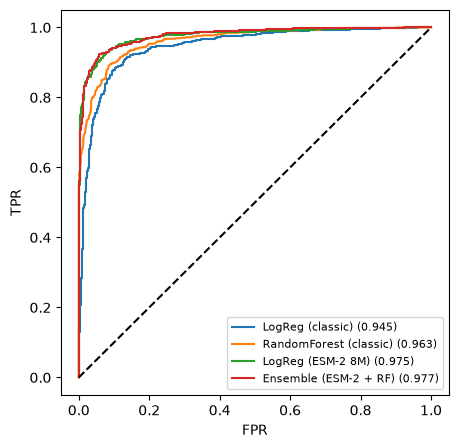

In [5]:
plt.figure(figsize=(5,5))
for k, p in probs.items():
    f, t, _ = roc_curve(y_te, p); plt.plot(f, t, label=f"{k} ({roc_auc_score(y_te,p):.3f})")
plt.plot([0,1],[0,1],"k--"); plt.xlabel("FPR"); plt.ylabel("TPR"); plt.legend(fontsize=8); plt.show()

## 4. Honest check: are test peptides just copies of training peptides?
For each test peptide I compute its highest 3-mer Jaccard similarity to any training peptide,
then re-score only the *least similar* test peptides.

In [6]:
def kmers(s, k=3): return {s[i:i+k] for i in range(len(s)-k+1)}
ref = [kmers(s) for s in tr_s + ev_s]
sim = np.array([max(len(q & r) / len(q | r) for r in ref if r) for q in map(kmers, te_s)])
low = sim < 0.2
print(f"{low.sum()} of {len(sim)} test peptides have similarity < 0.2 to every training peptide")
for k, p in probs.items():
    print(f"{k:24s} AUC on low-similarity subset = {roc_auc_score(y_te[low], p[low]):.3f}")

1108 of 1424 test peptides have similarity < 0.2 to every training peptide
LogReg (classic)         AUC on low-similarity subset = 0.924
RandomForest (classic)   AUC on low-similarity subset = 0.942
LogReg (ESM-2 8M)        AUC on low-similarity subset = 0.965
Ensemble (ESM-2 + RF)    AUC on low-similarity subset = 0.965


## Takeaways
* ESM-2 (only 8M parameters, frozen, no fine-tuning) + logistic regression beats hand-made features.
* Results are close to or above the published AMP Scanner v2 numbers on the same test split.
* Performance holds on test peptides with low similarity to training data.
* Caveat: ESM-2 was pre-trained on UniRef50, which may contain some of these peptides.